In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

In [106]:
from pathlib import Path
DATA_PATH = Path("..")  / "data" / "processed" / "labeled_sensor_data_clean.csv"
df = pd.read_csv(DATA_PATH)

In [107]:
df.shape

(17623, 34)

In [108]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17623 entries, 0 to 17622
Data columns (total 34 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   host_received_timestamp_utc  17623 non-null  object 
 1   device_time_ms               17623 non-null  int64  
 2   stage_elapsed_ms             17623 non-null  int64  
 3   condition                    17623 non-null  object 
 4   motor_running                17623 non-null  int64  
 5   motor_direction              17623 non-null  object 
 6   speed_percent                17623 non-null  int64  
 7   pwm_duty_8bit                17623 non-null  int64  
 8   ina219_ok                    17623 non-null  int64  
 9   power_data_valid             17623 non-null  int64  
 10  bus_voltage_v                17623 non-null  float64
 11  shunt_voltage_mv             17623 non-null  float64
 12  current_ma                   17623 non-null  float64
 13  power_mw        

In [109]:
df.head()

,host_received_timestamp_utc,device_time_ms,stage_elapsed_ms,condition,motor_running,motor_direction,speed_percent,pwm_duty_8bit,ina219_ok,power_data_valid,...,gyro_z_rad_s,encoder_count,encoder_delta,encoder_counts_per_second,rpm,overcurrent_fault,last_motor_stop_reason,label,fault_type,label_note
0,2026-10-28 04:14:13.983000+00:00,74978,200,normal,0,forward,0,0,1,1,...,-0.0061,0,0,0.0,0.0,0,keyboard_stop,0,none,NaN
1,2026-10-28 04:14:14.183000+00:00,75178,400,normal,0,forward,0,0,1,1,...,-0.0051,0,0,0.0,0.0,0,keyboard_stop,0,none,NaN
2,2026-10-28 04:14:14.383000+00:00,75378,600,normal,0,forward,0,0,1,1,...,-0.0056,0,0,0.0,0.0,0,keyboard_stop,0,none,NaN
3,2026-10-28 04:14:14.583000+00:00,75578,800,normal,0,forward,0,0,1,1,...,-0.0067,0,0,0.0,0.0,0,keyboard_stop,0,none,NaN
4,2026-10-28 04:14:14.783000+00:00,75778,1000,normal,0,forward,0,0,1,1,...,-0.0064,0,0,0.0,0.0,0,keyboard_stop,0,none,NaN


Label Distribution:
label
0    13870
1     3753
Name: count, dtype: int64


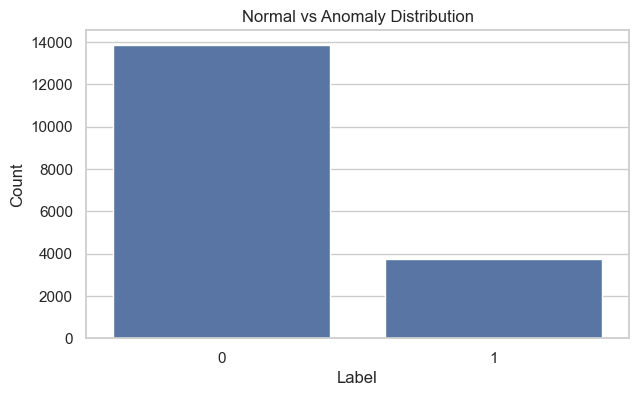

In [110]:
print("Label Distribution:")
print(df['label'].value_counts(dropna=False))

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='label')

plt.title("Normal vs Anomaly Distribution")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

condition
normal             13870
overheated          2792
vibration_issue      961
Name: count, dtype: int64


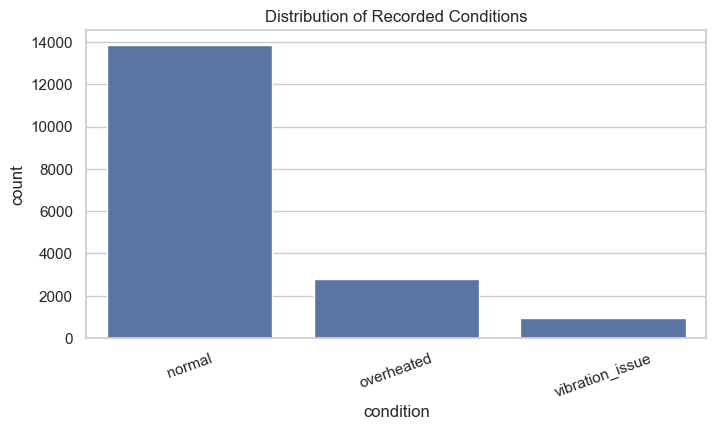

In [111]:
print(df['condition'].value_counts())

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='condition')

plt.title("Distribution of Recorded Conditions")
plt.xticks(rotation=20)
plt.show()

In [112]:
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2)
})

display(missing[missing['Missing Count'] > 0])

,Missing Count,Missing Percentage
label_note,17623,100.0


In [113]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 450


In [114]:
constant_cols = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("Constant Columns:")
print(constant_cols)

Constant Columns:
['motor_direction', 'ina219_ok', 'power_data_valid', 'ds18b20_ok', 'temperature_valid', 'mpu6050_ok', 'mpu_data_valid', 'overcurrent_fault', 'label_note']


In [115]:
# Create a working copy
df_clean = df.copy()

# Convert timestamp to datetime
df_clean['host_received_timestamp_utc'] = pd.to_datetime(
    df_clean['host_received_timestamp_utc'],
    errors='coerce',
    utc=True
)

# Sort records chronologically
df_clean = df_clean.sort_values(
    'host_received_timestamp_utc'
).reset_index(drop=True)

print("Working dataset shape:", df_clean.shape)

Working dataset shape: (17623, 34)


In [116]:
# Handle invalid temperature readings
df_clean.loc[
    df_clean['temperature_valid'] != 1,
    'temperature_c'
] = np.nan

print("Missing temperature:", df_clean['temperature_c'].isna().sum())
print("Missing RPM:", df_clean['rpm'].isna().sum()) 

Missing temperature: 0
Missing RPM: 0


In [117]:
print("Labeled records:", df_clean['label'].notna().sum())
print("Unlabeled records:", df_clean['label'].isna().sum())

Labeled records: 17623
Unlabeled records: 0


In [118]:
constant_cols = [
    col for col in df_clean.columns
    if df_clean[col].nunique(dropna=False) <= 1
]

print("Constant features:")
print(constant_cols)

Constant features:
['motor_direction', 'ina219_ok', 'power_data_valid', 'ds18b20_ok', 'temperature_valid', 'mpu6050_ok', 'mpu_data_valid', 'overcurrent_fault', 'label_note']


# Feature Engineering

Acceleration Magnitude

In [119]:
df_clean['acceleration_magnitude'] = np.sqrt(
    df_clean['accel_x_m_s2']**2 +
    df_clean['accel_y_m_s2']**2 +
    df_clean['accel_z_m_s2']**2
)

Gyroscope Magnitude

In [120]:
df_clean['gyro_magnitude'] = np.sqrt(
    df_clean['gyro_x_rad_s']**2 +
    df_clean['gyro_y_rad_s']**2 +
    df_clean['gyro_z_rad_s']**2
)

Speed When Running

In [121]:
df_clean['speed_when_running'] = (
    df_clean['speed_percent'] * df_clean['motor_running']
)

In [122]:
new_features = [
    'acceleration_magnitude',
    'gyro_magnitude',
    'speed_when_running'
]

display(df_clean[new_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
acceleration_magnitude,17623.0,9.455736,0.746952,6.515527,9.412462,9.435347,9.456893,85.830177
gyro_magnitude,17623.0,0.061355,0.157977,0.000000,0.029531,0.032700,0.039368,2.739461
speed_when_running,17623.0,58.959712,31.708543,0.000000,33.000000,65.000000,88.000000,100.000000


In [123]:
analysis_features = [
    'acceleration_magnitude',
    'gyro_magnitude',
    'temperature_c',
    'current_ma',
    'power_mw',
    'rpm'
]

display(
    df_clean.groupby('label')[analysis_features]
    .agg(['mean', 'std'])
    .round(3)
)

acceleration_magnitude        gyro_magnitude        temperature_c  \
                        mean    std           mean    std          mean   
label                                                                     
0                      9.443  0.413          0.034  0.031        26.129   
1                      9.501  1.410          0.162  0.317        40.604   

              current_ma          power_mw               rpm           
          std       mean     std      mean      std     mean      std  
label                                                                  
0       0.835    184.341  52.532  1636.928  549.015  217.210  141.384  
1      17.539    218.801  51.798  1499.859  353.422  187.828   95.726

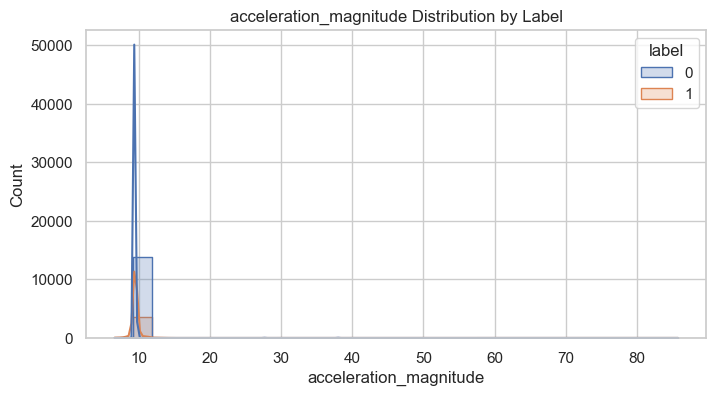

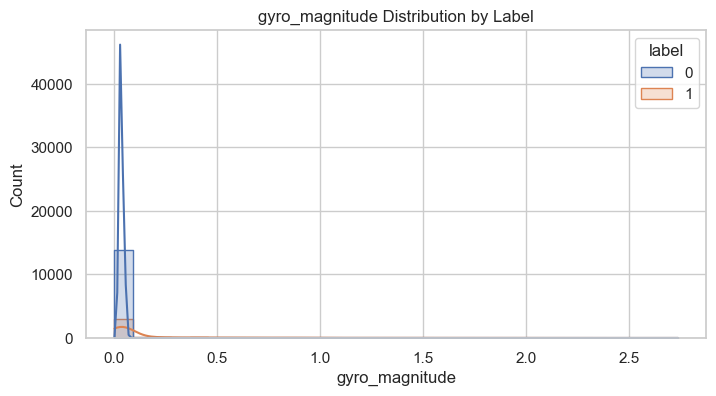

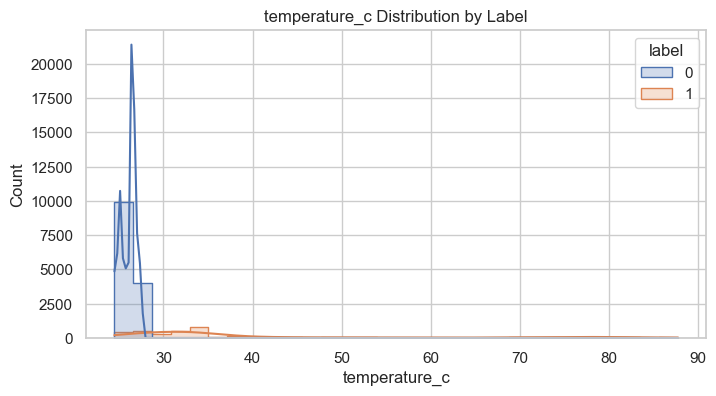

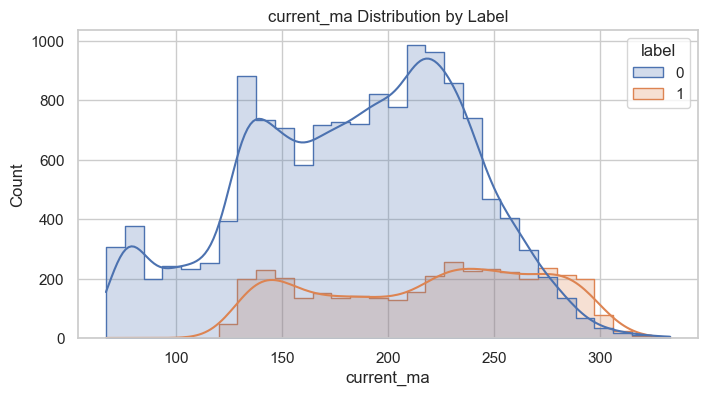

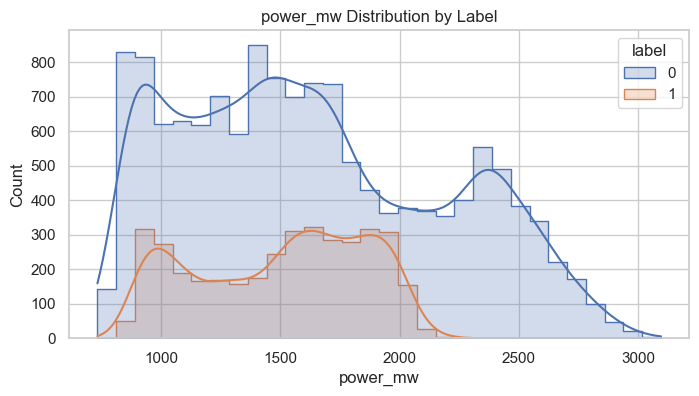

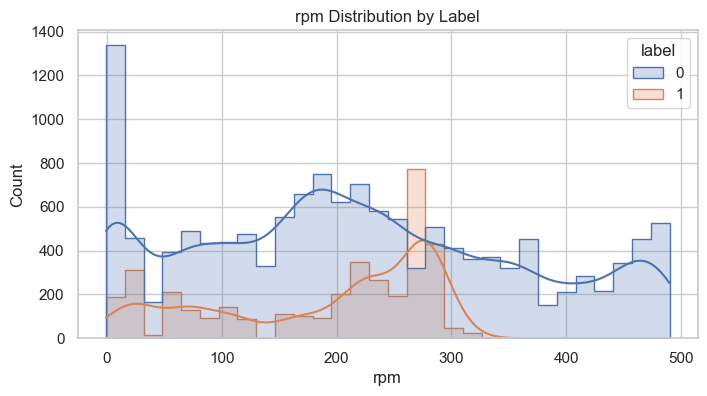

In [124]:
for feature in analysis_features:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df_clean,
        x=feature,
        hue='label',
        kde=True,
        bins=30,
        element='step'
    )

    plt.title(f'{feature} Distribution by Label')
    plt.show()

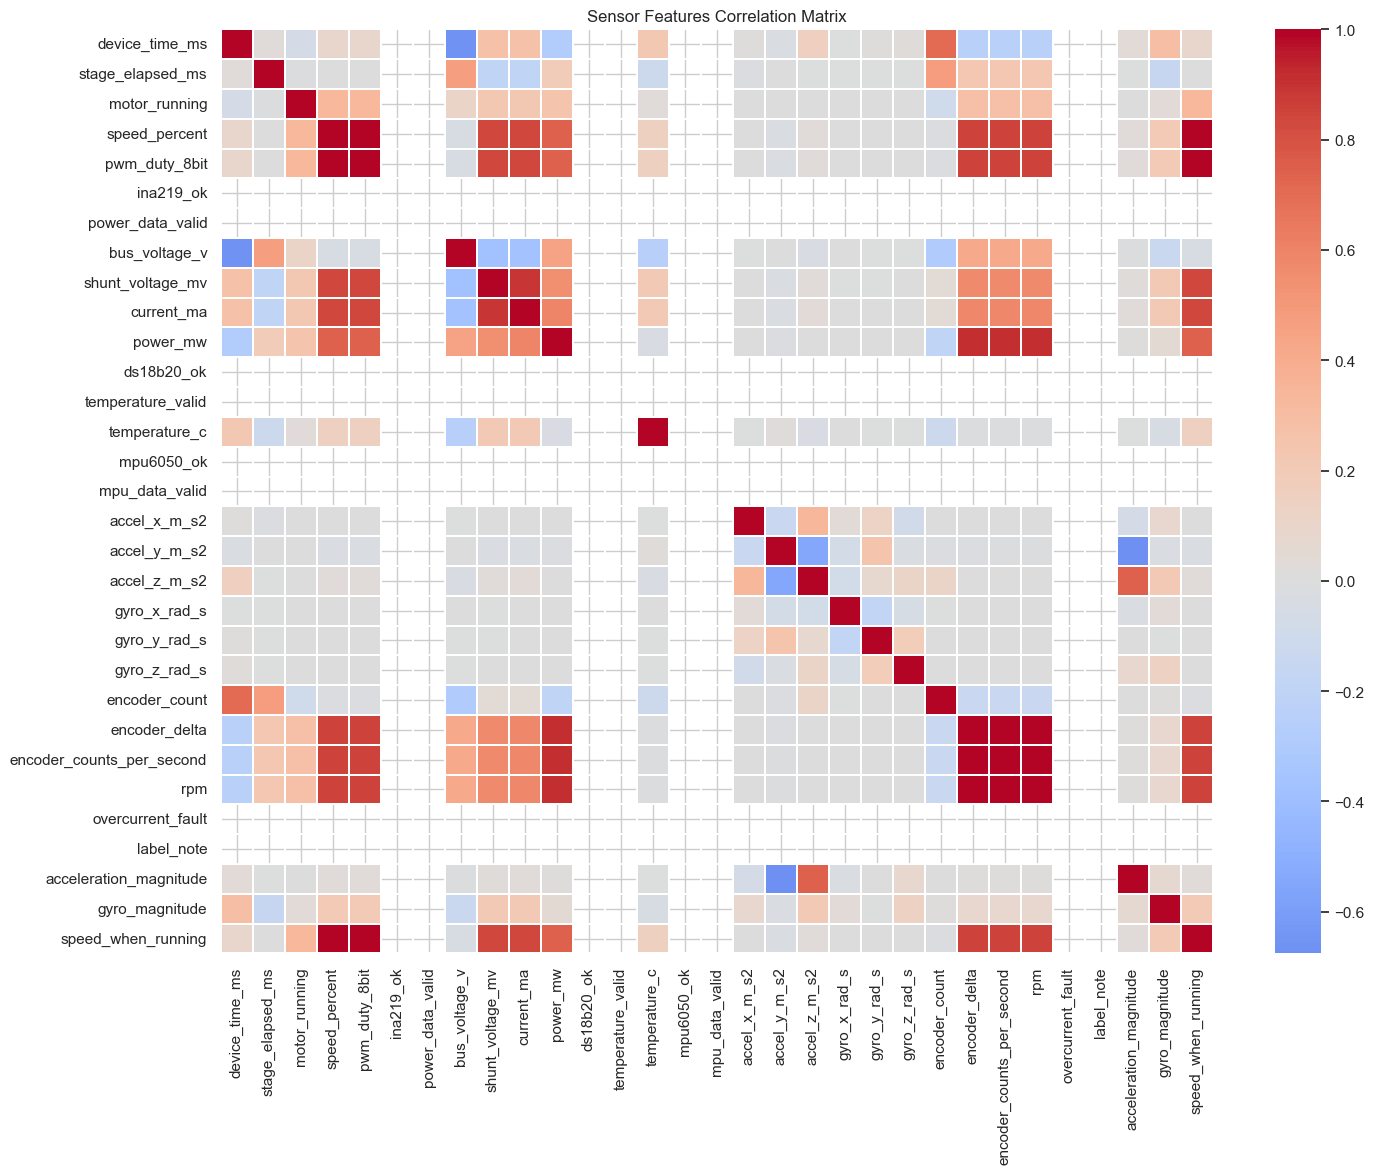

In [125]:
numeric_df = df_clean.select_dtypes(include=np.number)

correlation = numeric_df.drop(
    columns=['label'], errors='ignore'
).corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0,
    linewidths=0.3
)

plt.title("Sensor Features Correlation Matrix")
plt.show()

How closely each Feature relates to the Label

In [126]:
from sklearn.feature_selection import mutual_info_classif

# Use labeled records only
labeled_data = df_clean.dropna(subset=['label']).copy()

candidate_features = [
    'acceleration_magnitude',
    'gyro_magnitude',
    'speed_when_running',
    'temperature_c',
    'current_ma',
    'power_mw',
    'rpm',
    'encoder_delta',
    'encoder_counts_per_second'
]

X_mi = labeled_data[candidate_features].copy()
y_mi = labeled_data['label'].astype(int)

# Median imputation for exploratory analysis
X_mi = X_mi.fillna(X_mi.median())

mi_scores = mutual_info_classif(
    X_mi,
    y_mi,
    random_state=42
)

mi_results = pd.DataFrame({
    'Feature': candidate_features,
    'Mutual Information': mi_scores
}).sort_values(
    by='Mutual Information',
    ascending=False
)

display(mi_results)

,Feature,Mutual Information
3,temperature_c,0.416507
6,rpm,0.299446
8,encoder_counts_per_second,0.269279
7,encoder_delta,0.267712
2,speed_when_running,0.224476
1,gyro_magnitude,0.140674
0,acceleration_magnitude,0.107130
5,power_mw,0.072437
4,current_ma,0.068854


Summary

In [127]:
original_features = len(df.columns)
engineered_features = [
    'acceleration_magnitude',
    'gyro_magnitude',
    'speed_when_running'
]

print("Newly Engineered Features:")
for feature in engineered_features:
    print("-", feature)

print("\nTotal engineered features:", len(engineered_features))

Newly Engineered Features:
- acceleration_magnitude
- gyro_magnitude
- speed_when_running

Total engineered features: 3


# Chronological Block Splitting

In [128]:
BLOCK_SIZE = 50

SET_PATTERN = [
    "train",
    "train",
    "val",
    "train",
    "test"
]

RANDOM_STATE = 42

In [129]:
df_split = df_clean.copy()

df_split['block_position'] = (
    df_split.groupby('condition').cumcount()
)

df_split['block'] = (
    df_split['block_position'] // BLOCK_SIZE
)

df_split['split'] = (
    df_split['block'] % len(SET_PATTERN)
).map(lambda x: SET_PATTERN[x])

display(
    df_split[
        ['host_received_timestamp_utc',
         'condition', 'label', 'block', 'split']
    ].head(15)
)

,host_received_timestamp_utc,condition,label,block,split
0,2026-10-28 04:14:13.983000+00:00,normal,0,0,train
1,2026-10-28 04:14:14.183000+00:00,normal,0,0,train
2,2026-10-28 04:14:14.383000+00:00,normal,0,0,train
3,2026-10-28 04:14:14.583000+00:00,normal,0,0,train
4,2026-10-28 04:14:14.783000+00:00,normal,0,0,train
5,2026-10-28 04:14:14.983000+00:00,normal,0,0,train
6,2026-10-28 04:14:15.183000+00:00,normal,0,0,train
7,2026-10-28 04:14:15.383000+00:00,normal,0,0,train
8,2026-10-28 04:14:15.584000+00:00,normal,0,0,train
9,2026-10-28 04:14:15.784000+00:00,normal,0,0,train


In [130]:
labeled_df = df_split.dropna(
    subset=['label', 'condition']
).copy()

labeled_df['label'] = labeled_df['label'].astype(int)

print("Labeled dataset shape:", labeled_df.shape)
print("Unlabeled records excluded:", df_split['label'].isna().sum())

Labeled dataset shape: (17623, 40)
Unlabeled records excluded: 0


In [131]:
split_summary = (
    labeled_df.groupby(['split', 'condition'])
    .size()
    .unstack(fill_value=0)
    .reindex(['train', 'val', 'test'])
)

display(split_summary)

condition,normal,overheated,vibration_issue
split,,,
train,8350,1692,600
val,2770,550,200
test,2750,550,161


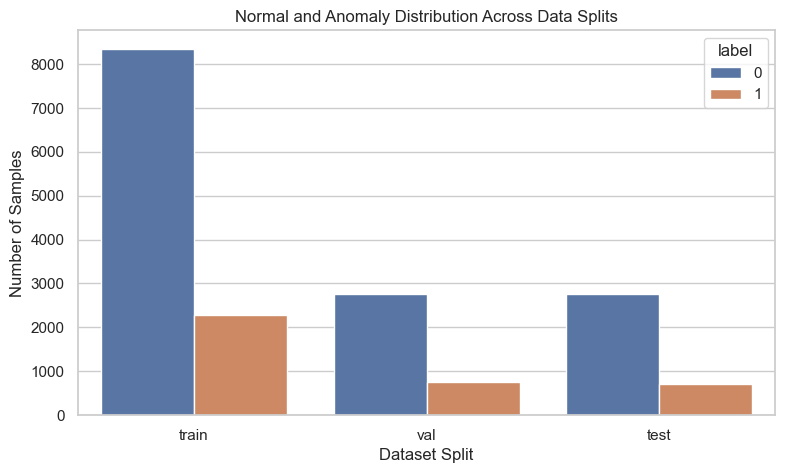

In [132]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=labeled_df,
    x='split',
    hue='label',
    order=['train', 'val', 'test']
)

plt.title("Normal and Anomaly Distribution Across Data Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Samples")
plt.show()

# Feature Selection

In [133]:
BASE_FEATURES = [
    "motor_running", "speed_percent", "pwm_duty_8bit",
    "bus_voltage_v", "shunt_voltage_mv", "current_ma", "power_mw",
    "temperature_c", "accel_x_m_s2", "accel_y_m_s2", "accel_z_m_s2",
    "gyro_x_rad_s", "gyro_y_rad_s", "gyro_z_rad_s",
    "encoder_delta", "encoder_counts_per_second", "rpm"
]

HEALTH_FEATURES = [
    "ina219_ok", "power_data_valid", "ds18b20_ok",
    "temperature_valid", "mpu6050_ok", "mpu_data_valid", "rpm_valid"
]

ENGINEERED_FEATURES = [
    "acceleration_magnitude",
    "gyro_magnitude",
    "speed_when_running"
]

EXCLUDED_COLUMNS = {
    "host_received_timestamp_utc", "condition", "label",
    "fault_type", "last_motor_stop_reason",
    "motor_direction", "data_source",
    "device_time_ms", "stage_elapsed_ms", "label_note"
}

candidate_features = [
    col for col in BASE_FEATURES + HEALTH_FEATURES + ENGINEERED_FEATURES
    if col in labeled_df.columns and col not in EXCLUDED_COLUMNS
]

print("Candidate Features:", len(candidate_features))
print(candidate_features)

Candidate Features: 26
['motor_running', 'speed_percent', 'pwm_duty_8bit', 'bus_voltage_v', 'shunt_voltage_mv', 'current_ma', 'power_mw', 'temperature_c', 'accel_x_m_s2', 'accel_y_m_s2', 'accel_z_m_s2', 'gyro_x_rad_s', 'gyro_y_rad_s', 'gyro_z_rad_s', 'encoder_delta', 'encoder_counts_per_second', 'rpm', 'ina219_ok', 'power_data_valid', 'ds18b20_ok', 'temperature_valid', 'mpu6050_ok', 'mpu_data_valid', 'acceleration_magnitude', 'gyro_magnitude', 'speed_when_running']


In [134]:
normal_train_mask = (
    (labeled_df['split'] == 'train') &
    (labeled_df['label'] == 0)
)

X_candidates = labeled_df[candidate_features].apply(
    pd.to_numeric, errors='coerce'
)

varying_features = (
    X_candidates.loc[normal_train_mask]
    .nunique(dropna=True) > 1
)

selected_features = varying_features[
    varying_features
].index.tolist()

dropped_features = varying_features[
    ~varying_features
].index.tolist()

print("Selected Features:", selected_features)
print("\nDropped Features:", dropped_features)

Selected Features: ['motor_running', 'speed_percent', 'pwm_duty_8bit', 'bus_voltage_v', 'shunt_voltage_mv', 'current_ma', 'power_mw', 'temperature_c', 'accel_x_m_s2', 'accel_y_m_s2', 'accel_z_m_s2', 'gyro_x_rad_s', 'gyro_y_rad_s', 'gyro_z_rad_s', 'encoder_delta', 'encoder_counts_per_second', 'rpm', 'acceleration_magnitude', 'gyro_magnitude', 'speed_when_running']

Dropped Features: ['ina219_ok', 'power_data_valid', 'ds18b20_ok', 'temperature_valid', 'mpu6050_ok', 'mpu_data_valid']


# Model-Specific Preprocessing

In [135]:
%pip install pipelines

Defaulting to user installation because normal site-packages is not writeable
  Using cached pipelines-0.0.14.tar.gz (161 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Using cached futures-3.0.5.tar.gz (25 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Using cached Jinja2-2.8-py2.py3-none-any.whl.metadata (2.1 kB)
  Using cached PyYAML-3.11.zip (371 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Using cached requests-2.9.1-py2.py3-none-any.whl.metadata (36 kB)
  Using cached sh-1.11.tar.gz (36 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> [21 lines of output]
      C:\Users\Sahar Elgebaly\AppData\Local\Temp\pip-install-t89hpvyi\sh_c1d6632def2447f0b3c028f0247c9cfb\sh.py:232: SyntaxWarning: invalid escape sequence '\d'
        rc_exc_regex = re.compile("(ErrorReturnCode|SignalException)_((\d+)|SIG\w+)")
      Traceback (most recent call last):
        File "<string>", line 2, in <module>
          exec(compile('''
          ~~~~^^^^^^^^^^^^
          # This is <pip-setuptools-caller> -- a caller that pip uses to run setup.py
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
          ...<32 lines>...
          exec(compile(setup_py_code, filename, "exec"))
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
          ''' % ('C:\\Users\\Sahar Elgebaly\\AppData\\Local\\Temp\\pip-install-t89hpvyi\\sh_c1d6632def2447f0b3c028f0247c9cfb\\setup.py',), "<pip-setuptools-call

In [136]:
from pathlib import Path
print(list(Path("..").rglob("pipelines*")))

[WindowsPath('../script/pipelines.py'), WindowsPath('../script/__pycache__/pipelines.cpython-313.pyc')]


In [137]:
import sys
from pathlib import Path
sys.path.append(str((Path("..") / "script").resolve()))
from pipelines import MODEL_KEYS, PREPROCESSING_TEXT, build_preprocessor
print("Available Models:", MODEL_KEYS)

Available Models: ['robust_baseline', 'isolation_forest', 'lof', 'ocsvm', 'autoencoder']


In [138]:
# Selected features
X = labeled_df[selected_features].apply(
    pd.to_numeric, errors='coerce'
)

y = labeled_df['label'].astype(int)

# Split masks
train_mask = labeled_df['split'].eq('train')
val_mask = labeled_df['split'].eq('val')
test_mask = labeled_df['split'].eq('test')

# Normal training samples only
fit_mask = train_mask & y.eq(0)

X_train = X.loc[train_mask]
X_val = X.loc[val_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_val = y.loc[val_mask]
y_test = y.loc[test_mask]

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

print("\nNormal training samples:", fit_mask.sum())

Training Shape: (10642, 20)
Validation Shape: (3520, 20)
Testing Shape: (3461, 20)

Normal training samples: 8350


In [139]:
x_fit = X.loc[fit_mask].to_numpy()

preprocessors = {}

for key in MODEL_KEYS:

    preprocessor = build_preprocessor(key)

    preprocessor.fit(x_fit)

    preprocessors[key] = preprocessor

    print(f"{key} preprocessor fitted successfully.")

robust_baseline preprocessor fitted successfully.
isolation_forest preprocessor fitted successfully.
lof preprocessor fitted successfully.
ocsvm preprocessor fitted successfully.
autoencoder preprocessor fitted successfully.


In [140]:
processed_data = {}

for key, preprocessor in preprocessors.items():

    processed_data[key] = {
        'X_train': preprocessor.transform(X_train.to_numpy()),
        'X_val': preprocessor.transform(X_val.to_numpy()),
        'X_test': preprocessor.transform(X_test.to_numpy())
    }

    print(f"\n{key}")

    for split_name, data in processed_data[key].items():
        print(f"{split_name}: {data.shape}")


robust_baseline
X_train: (10642, 20)
X_val: (3520, 20)
X_test: (3461, 20)

isolation_forest
X_train: (10642, 20)
X_val: (3520, 20)
X_test: (3461, 20)

lof
X_train: (10642, 20)
X_val: (3520, 20)
X_test: (3461, 20)

ocsvm
X_train: (10642, 20)
X_val: (3520, 20)
X_test: (3461, 20)

autoencoder
X_train: (10642, 20)
X_val: (3520, 20)
X_test: (3461, 20)


# Final Dataset Preparation

In [141]:
for key, data in processed_data.items():

    print(f"\nModel: {key}")

    for split_name, values in data.items():

        print(
            f"{split_name}: "
            f"Shape = {values.shape}, "
            f"NaN = {np.isnan(values).sum()}"
        )


Model: robust_baseline
X_train: Shape = (10642, 20), NaN = 0
X_val: Shape = (3520, 20), NaN = 0
X_test: Shape = (3461, 20), NaN = 0

Model: isolation_forest
X_train: Shape = (10642, 20), NaN = 0
X_val: Shape = (3520, 20), NaN = 0
X_test: Shape = (3461, 20), NaN = 0

Model: lof
X_train: Shape = (10642, 20), NaN = 0
X_val: Shape = (3520, 20), NaN = 0
X_test: Shape = (3461, 20), NaN = 0

Model: ocsvm
X_train: Shape = (10642, 20), NaN = 0
X_val: Shape = (3520, 20), NaN = 0
X_test: Shape = (3461, 20), NaN = 0

Model: autoencoder
X_train: Shape = (10642, 20), NaN = 0
X_val: Shape = (3520, 20), NaN = 0
X_test: Shape = (3461, 20), NaN = 0


In [142]:
for split_name, target in [
    ('Train', y_train),
    ('Validation', y_val),
    ('Test', y_test)
]:

    print(f"\n{split_name} Distribution:")

    print(target.value_counts().sort_index())

    print(
        "Normal:",
        (target == 0).sum()
    )

    print(
        "Anomaly:",
        (target == 1).sum()
    )


Train Distribution:
label
0    8350
1    2292
Name: count, dtype: int64
Normal: 8350
Anomaly: 2292

Validation Distribution:
label
0    2770
1     750
Name: count, dtype: int64
Normal: 2770
Anomaly: 750

Test Distribution:
label
0    2750
1     711
Name: count, dtype: int64
Normal: 2750
Anomaly: 711


In [143]:
split_sizes = pd.DataFrame({
    'Dataset': ['Train', 'Validation', 'Test'],
    'Total Samples': [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    'Normal Samples': [
        (y_train == 0).sum(),
        (y_val == 0).sum(),
        (y_test == 0).sum()
    ],
    'Anomaly Samples': [
        (y_train == 1).sum(),
        (y_val == 1).sum(),
        (y_test == 1).sum()
    ]
})

display(split_sizes)

,Dataset,Total Samples,Normal Samples,Anomaly Samples
0,Train,10642,8350,2292
1,Validation,3520,2770,750
2,Test,3461,2750,711
